# Step 1 — Download the A-section scans

Continue from Katherine's `api_look.ipynb`. Download printed pages **161–162** and keep their source mapping. Our initial sample is the **53 personal entries on page 161**, from **Aalto J** to **Abberton T Frank**. Page 162 is extension/context only. Companies remain visible in the complete scans but are not counted.

This notebook calls a small reusable script. It does not run OCR, extract analytical fields, or create a gold-standard transcription. No additional Python packages are needed for the download.


In [1]:
from pathlib import Path
import csv
import subprocess
import sys

# Locate the script from the notebook folder, repo root, or project workspace.
candidates = [
    base / prefix / "fa26/scripts/download_a_sample.py"
    for base in (Path.cwd(), *Path.cwd().parents)
    for prefix in ("", "ds-bpl-city-directories")
]
script = next((path for path in candidates if path.is_file()), None)
if script is None:
    raise FileNotFoundError("Open this notebook inside ds-bpl-city-directories.")
output = script.parents[1] / "data/a_sample"
print("Script:", script)
print("Output:", output)


Script: /Users/yly/Documents/ChatGPT/Spark BPL Project/ds-bpl-city-directories/fa26/scripts/download_a_sample.py
Output: /Users/yly/Documents/ChatGPT/Spark BPL Project/ds-bpl-city-directories/fa26/data/a_sample


## Download and build the source indexes

The script reuses Katherine's Internet Archive item identifier and metadata API. It reads `scandata.xml` to map printed pages to scan leaves and the IIIF manifest to obtain the image URLs. Each image is downloaded separately; the full JP2 ZIP is not required. Re-running reuses cached files.


In [2]:
subprocess.run([sys.executable, str(script)], check=True)


Cached: metadata.json
Cached: scandata.xml
Cached: iiif_manifest.json
Cached: bostonmassachuse1916112samp_leaf0163_p161.jpg
Cached: bostonmassachuse1916112samp_leaf0164_p162.jpg

Saved 2 scans and their page mappings to /Users/yly/Documents/ChatGPT/Spark BPL Project/ds-bpl-city-directories/fa26/data/a_sample
Indexed 53 personal entries on printed page 161.
Next: review the selection, then transcribe/parse the selected entries.


CompletedProcess(args=['/Users/yly/Desktop/DS701/.venv/bin/python', '/Users/yly/Documents/ChatGPT/Spark BPL Project/ds-bpl-city-directories/fa26/scripts/download_a_sample.py'], returncode=0)

## Check the page mapping

Printed page, scan leaf, and IIIF canvas index are different identifiers. The mapping must come from the source metadata, not an assumed offset.


In [3]:
with (output / "pages.csv").open(encoding="utf-8", newline="") as handle:
    pages = list(csv.DictReader(handle))
for page in pages:
    print(f"Printed page {page['printed_page']} -> leaf {page['leaf_num']} "
          f"-> canvas index {page['canvas_index_0based']}")
    print("Source:", page["source_page_url"])
    print("Local scan:", output / page["local_image"])


Printed page 161 -> leaf 163 -> canvas index 162
Source: https://archive.org/details/bostonmassachuse1916112samp/page/161/mode/1up
Local scan: /Users/yly/Documents/ChatGPT/Spark BPL Project/ds-bpl-city-directories/fa26/data/a_sample/images/bostonmassachuse1916112samp_leaf0163_p161.jpg
Printed page 162 -> leaf 164 -> canvas index 163
Source: https://archive.org/details/bostonmassachuse1916112samp/page/162/mode/1up
Local scan: /Users/yly/Documents/ChatGPT/Spark BPL Project/ds-bpl-city-directories/fa26/data/a_sample/images/bostonmassachuse1916112samp_leaf0164_p162.jpg


## View the first A-section page

The abbreviation key occupies the upper part of page 161. Listings are below it: read the left column first, then the right. Open the JPEG separately to inspect small details at full resolution.


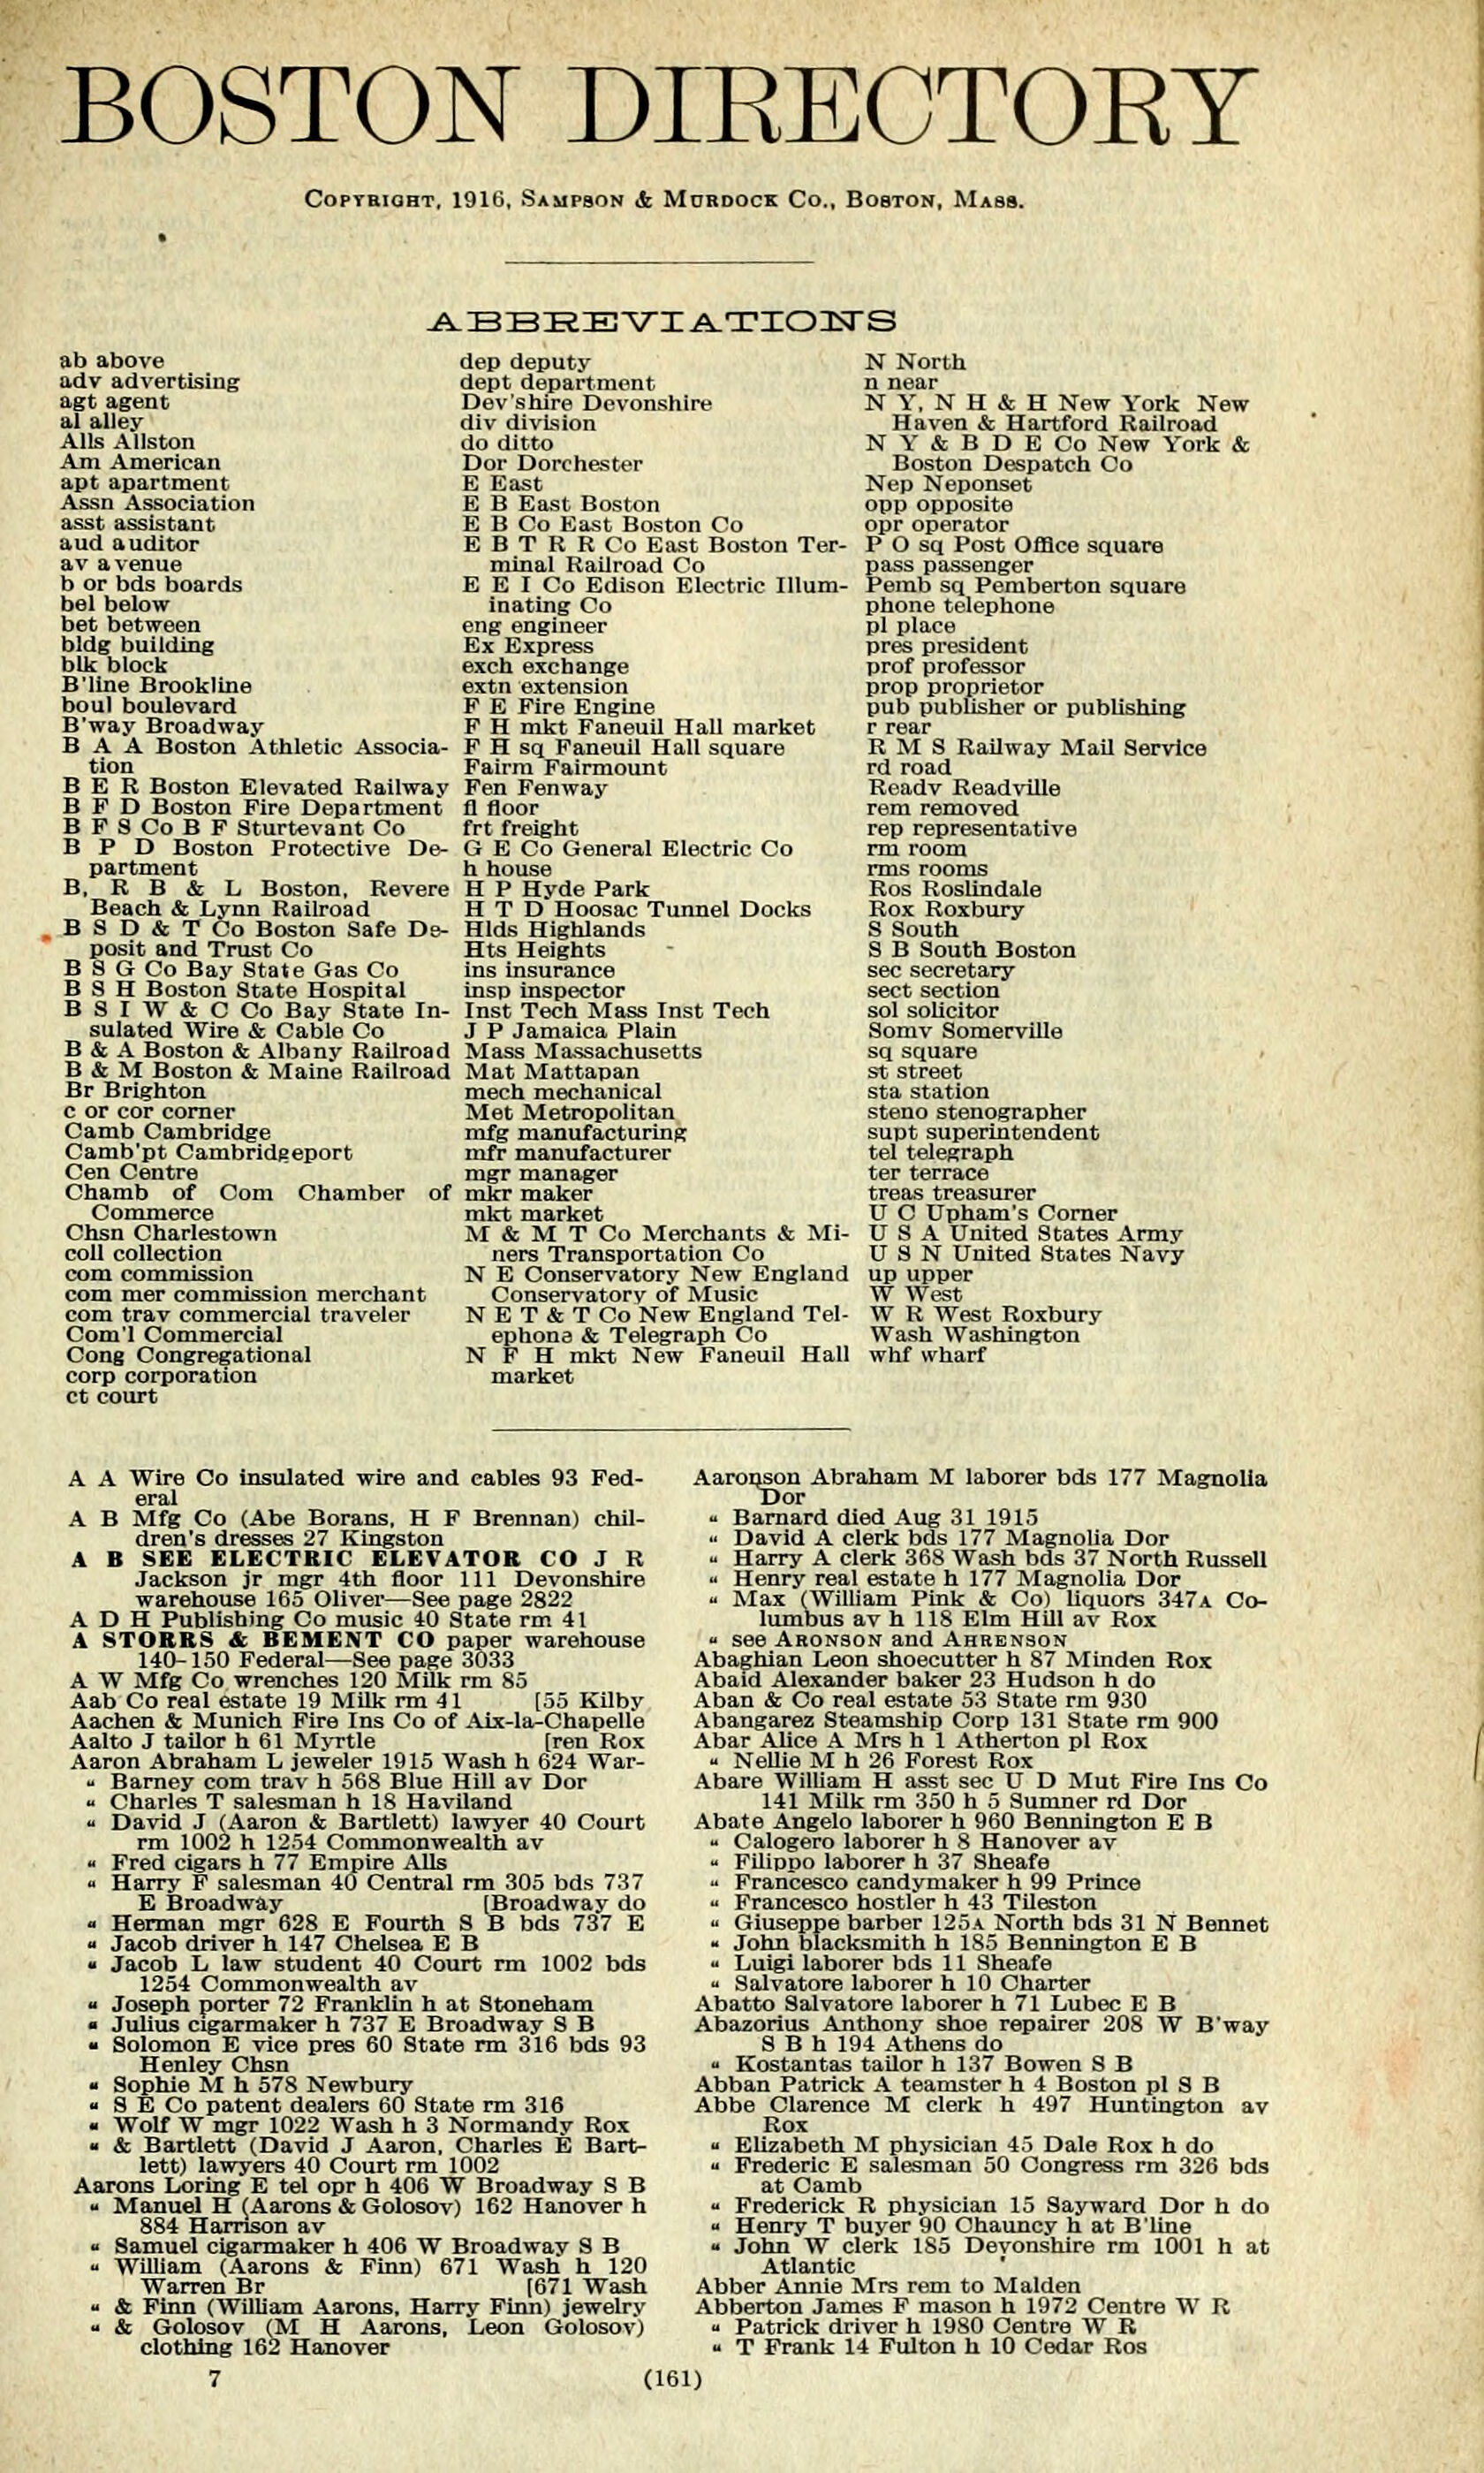

In [4]:
from IPython.display import Image, display

first_page = next(page for page in pages if page["printed_page"] == "161")
display(Image(filename=str(output / first_page["local_image"]), width=850))


## Check the selection boundary

The manually curated locator list contains 19 personal entries on the left and 34 on the right. It includes one death notice and one removal notice, flagged for later review. Labels are navigation aids with surnames written out; they are not as-is transcription or validated gold answers.


In [5]:
with (output / "sample_index.csv").open(encoding="utf-8", newline="") as handle:
    sample = list(csv.DictReader(handle))
print("Personal entries:", len(sample))
print("Start:", sample[0]["sample_id"], sample[0]["locator_label"])
print("End:", sample[-1]["sample_id"], sample[-1]["locator_label"])
for row in sample:
    if row["notice"]:
        print("Notice:", row["sample_id"], row["locator_label"], "—", row["notice"])


Personal entries: 53
Start: A001 Aalto J
End: A053 Abberton T Frank
Notice: A021 Aaronson Barnard — died Aug 31 1915
Notice: A050 Abber Annie Mrs — rem to Malden


**Step 1 is complete when the two scans, `pages.csv`, and `sample_index.csv` exist.** Review the 53-entry selection with the team, then open `02_extract_a_sample.ipynb` to prepare the first-pass structured table and image checks for the same records. See `fa26/data/a_sample/README.md` for definitions, limitations and reproduction instructions.
